# Network Intrusion Detection System (IDS) — Upgraded Pipeline
### A Justified, End-to-End ML Approach

This notebook presents a rigorous, step-by-step intrusion detection pipeline where **every design decision is justified** with statistical or theoretical reasoning. The pipeline covers:

1. Data Loading & Quality Analysis
2. Label Consolidation & Class Distribution
3. **Feature Engineering & Selection** (variance filtering → correlation pruning → importance-based selection)
4. **Principled Sampling** (SMOTETomek — synthetic oversampling + Tomek link cleaning)
5. Train / Validation / Test Split
6. **Model Justification & Baseline Comparison**
7. XGBoost Training with Regularisation
8. Deep Neural Network Training
9. **Overfitting Analysis** (learning curves, cross-validation)
10. Ensemble & Threshold Tuning
11. Final Evaluation & Confusion Matrix

---
## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, pickle, warnings, os
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import VarianceThreshold, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample as sk_resample

from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

import tensorflow as tf
from keras import layers, regularizers, callbacks

os.makedirs('plots', exist_ok=True)

print('All libraries loaded successfully.')
print(f'TensorFlow version: {tf.__version__}')

All libraries loaded successfully.
TensorFlow version: 2.21.0


---
## 2. Data Loading

We load the pre-processed dataset produced by `upgraded_dataProc.py`.
That script already handled: duplicate removal, NaN/Inf cleaning, and label consolidation.
We verify the loaded data is as expected before proceeding.

In [2]:
# Load the cleaned, label-consolidated dataset from dataProc.py
# dataProc.py already: removed duplicates, removed NaN/Inf, consolidated labels
df = pd.read_csv('Dataset/ProcessedData.csv')

print(f'Loaded ProcessedData.csv: {df.shape}')
print(f'\nColumns: {df.columns.tolist()}')
print(f'\nClass distribution:')
print(df['Attack_Group'].value_counts())
print(f'\nMissing values: {df.isnull().sum().sum()}')
print(f'Inf values: {np.isinf(df.select_dtypes(include=[np.number])).sum().sum()}')

Loaded ProcessedData.csv: (9167220, 58)

Columns: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'SYN Flag Count', 'URG Flag Count', 'Avg Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Init Fwd Win Bytes', 'Init Bwd Win Bytes', 'Fwd

> **Note:** Data cleaning (deduplication, NaN/Inf removal) was performed in `upgraded_dataProc.py`. No further cleaning needed here.

---
## 3. Class Distribution

Label consolidation was performed in `upgraded_dataProc.py`. Here we visualise
the class distribution to motivate the SMOTETomek sampling strategy.

In [3]:
# Attack_Group is already consolidated — just visualise distribution
dist = df['Attack_Group'].value_counts()
print('Class distribution:')
print(dist)
print(f'\nImbalance ratio (Normal/smallest): {dist["Normal"] / dist.min():.0f}x')

Class distribution:
Attack_Group
Normal               7185841
DDoS                 1234722
DoS                   397338
Botnet                145968
BruteForce            105264
Infiltration           94857
LowSeverityAttack       3230
Name: count, dtype: int64

Imbalance ratio (Normal/smallest): 2225x


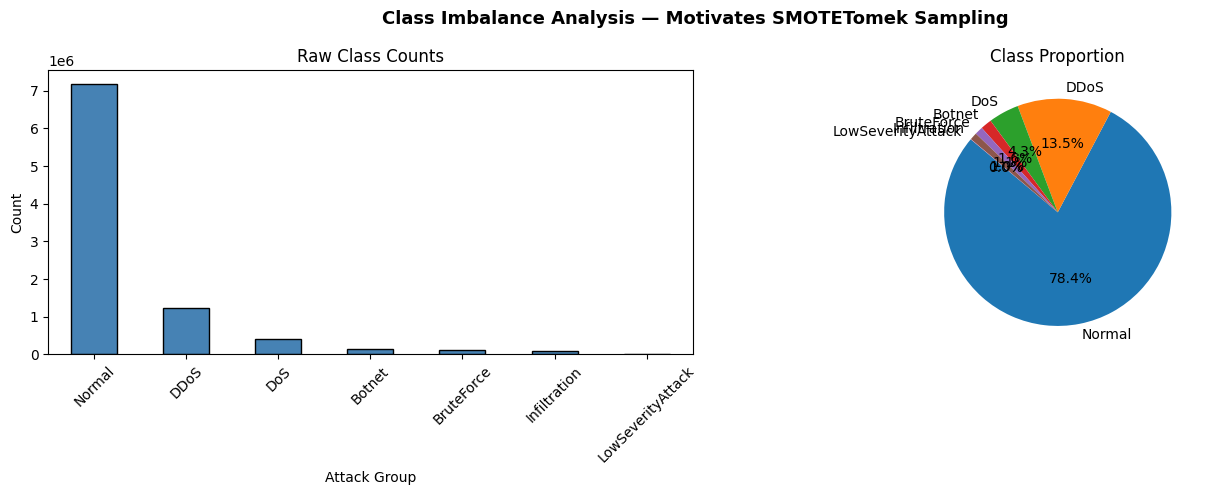

In [4]:
# Visualise class imbalance — this motivates the sampling strategy in Section 5
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dist.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Raw Class Counts')
axes[0].set_xlabel('Attack Group')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

axes[1].pie(dist, labels=dist.index, autopct='%1.1f%%', startangle=140)
axes[1].set_title('Class Proportion')

plt.suptitle('Class Imbalance Analysis — Motivates SMOTETomek Sampling', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 4. Feature Selection

Using all 57 raw features introduces noise, multicollinearity, and makes models prone to overfitting. We apply a **three-stage feature selection pipeline**:

| Stage | Technique | Justification |
|---|---|---|
| 1 | **Variance Threshold** | Features with near-zero variance carry no discriminative signal |
| 2 | **Correlation Pruning** | Highly correlated features (r > 0.95) are redundant and inflate model complexity |
| 3 | **XGBoost Feature Importance** | Model-based selection retains only features that actively reduce impurity |

In [5]:
X_all = df.drop(columns=['Attack_Group']).reset_index(drop=True)
y_all = df['Attack_Group'].reset_index(drop=True)

# --- Stage 1: Variance Threshold ---
# Features with variance < 0.01 are effectively constant across samples.
# A constant feature cannot help a classifier distinguish between classes.
vt = VarianceThreshold(threshold=0.01)
vt.fit(X_all)
low_var_cols = X_all.columns[~vt.get_support()].tolist()
X_var = X_all.loc[:, vt.get_support()]

print(f'Stage 1 — Variance Threshold:')
print(f'  Removed {len(low_var_cols)} low-variance features: {low_var_cols}')
print(f'  Remaining features: {X_var.shape[1]}')

Stage 1 — Variance Threshold:
  Removed 0 low-variance features: []
  Remaining features: 57


Stage 2 — Correlation Pruning (threshold=0.95):
  Removed 22 highly correlated features: ['Bwd Packets Length Total', 'Fwd Packet Length Std', 'Bwd Packet Length Std', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Fwd Packets/s', 'Packet Length Std', 'Avg Packet Size', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Fwd Act Data Packets', 'Idle Mean', 'Idle Std', 'Idle Max']
  Remaining features: 35


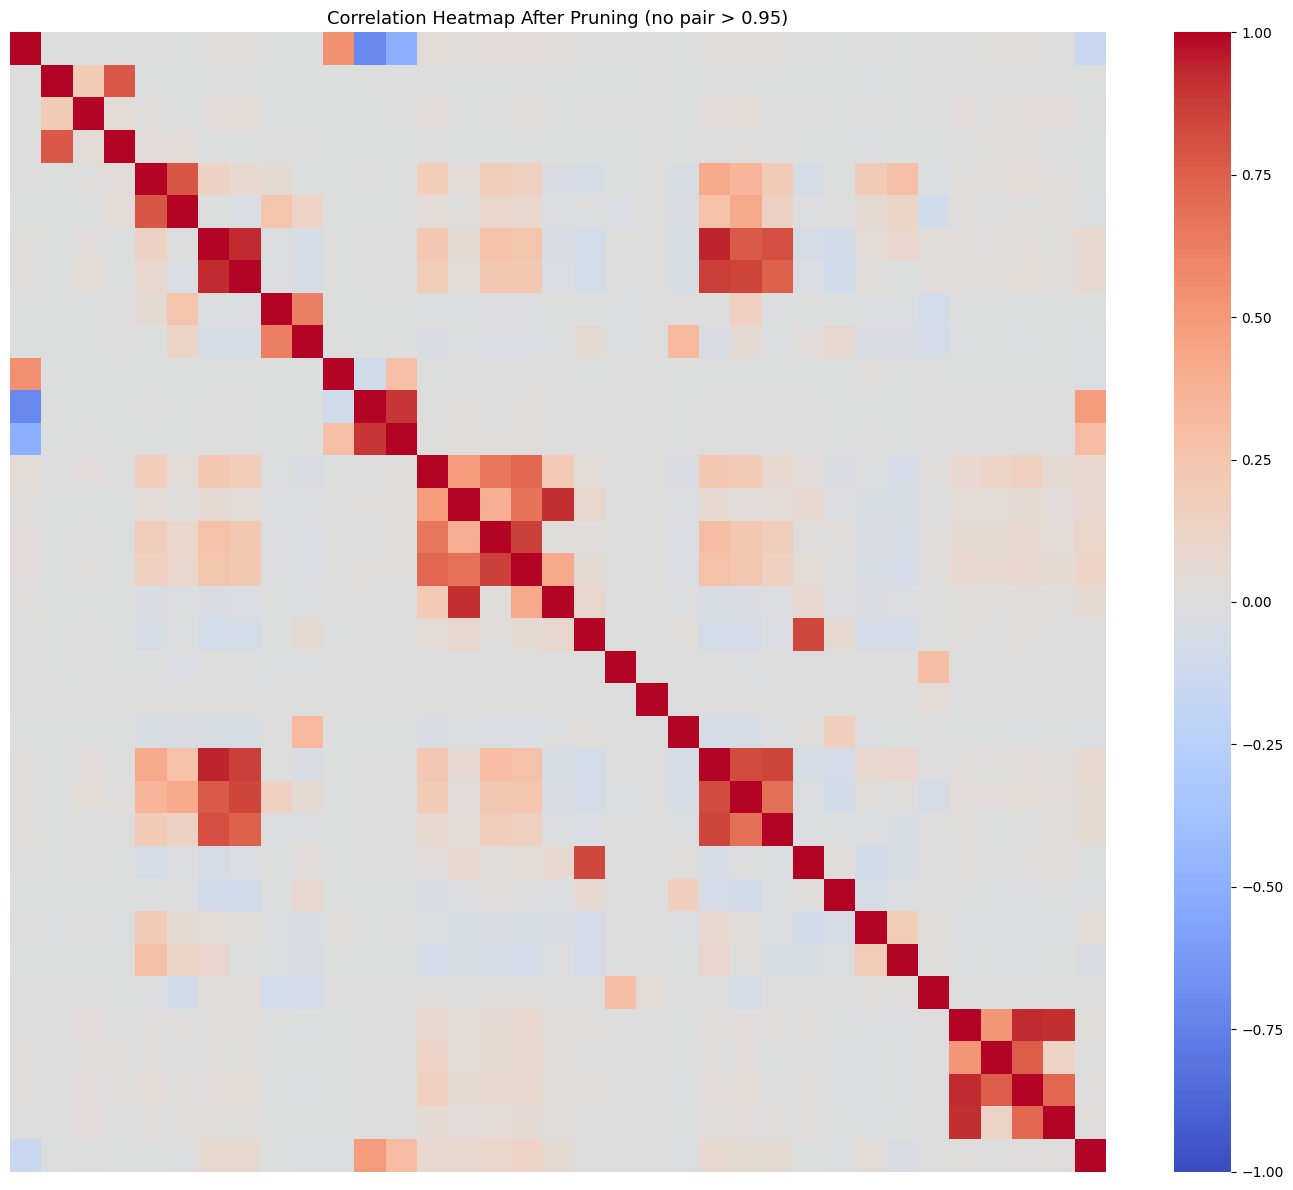

In [6]:
# --- Stage 2: Correlation Pruning ---
# When two features have |r| > 0.95, they are nearly linearly dependent.
# Keeping both adds no new information but increases model complexity and
# can destabilise coefficient-based models. We drop the second of each pair.

corr_matrix = X_var.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop_corr = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]
X_corr = X_var.drop(columns=to_drop_corr)

print(f"Stage 2 — Correlation Pruning (threshold=0.95):")
print(f"  Removed {len(to_drop_corr)} highly correlated features: {to_drop_corr}")
print(f"  Remaining features: {X_corr.shape[1]}")

# Plot heatmap of remaining features
plt.figure(figsize=(14, 12))
sns.heatmap(X_corr.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title('Correlation Heatmap After Pruning (no pair > 0.95)', fontsize=13)
plt.tight_layout()
plt.savefig('plots/02_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
# --- Stage 3: XGBoost Feature Importance (SelectFromModel) ---
# We train a shallow XGBoost on a stratified subsample to estimate feature
# importance scores. Features above mean importance are retained.
# This is a data-driven, model-aware selection that considers feature interactions.

le = LabelEncoder()
# Reset index to ensure clean alignment between X_corr and y_all
X_corr_reset = X_corr.reset_index(drop=True)
y_encoded = le.fit_transform(y_all)  # y_all already reset above
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
print('Label encoding:', label_map)

# Subsample for fast importance estimation (10% stratified)
X_sub, _, y_sub, _ = train_test_split(
    X_corr_reset, y_encoded, test_size=0.9,
    stratify=y_encoded, random_state=42
)

n_classes = len(le.classes_)
xgb_selector = XGBClassifier(
    n_estimators=100, max_depth=5, learning_rate=0.1,
    objective='multi:softprob', num_class=n_classes,
    tree_method='hist', eval_metric='mlogloss',
    n_jobs=-1, random_state=42
)
xgb_selector.fit(X_sub, y_sub)

# Select features above mean importance
sfm = SelectFromModel(xgb_selector, threshold='mean', prefit=True)
selected_mask = sfm.get_support()
selected_features = X_corr_reset.columns[selected_mask].tolist()

print(f'\nStage 3 — XGBoost Feature Importance (threshold=mean):')
print(f'  Selected {len(selected_features)} from {X_corr_reset.shape[1]} features')
print(f'  Selected features: {selected_features}')

Label encoding: {'Botnet': np.int64(0), 'BruteForce': np.int64(1), 'DDoS': np.int64(2), 'DoS': np.int64(3), 'Infiltration': np.int64(4), 'LowSeverityAttack': np.int64(5), 'Normal': np.int64(6)}

Stage 3 — XGBoost Feature Importance (threshold=mean):
  Selected 15 from 35 features
  Selected features: ['Total Fwd Packets', 'Fwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd IAT Std', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Bwd Packets/s', 'Packet Length Mean', 'Packet Length Variance', 'Init Fwd Win Bytes', 'Fwd Seg Size Min']


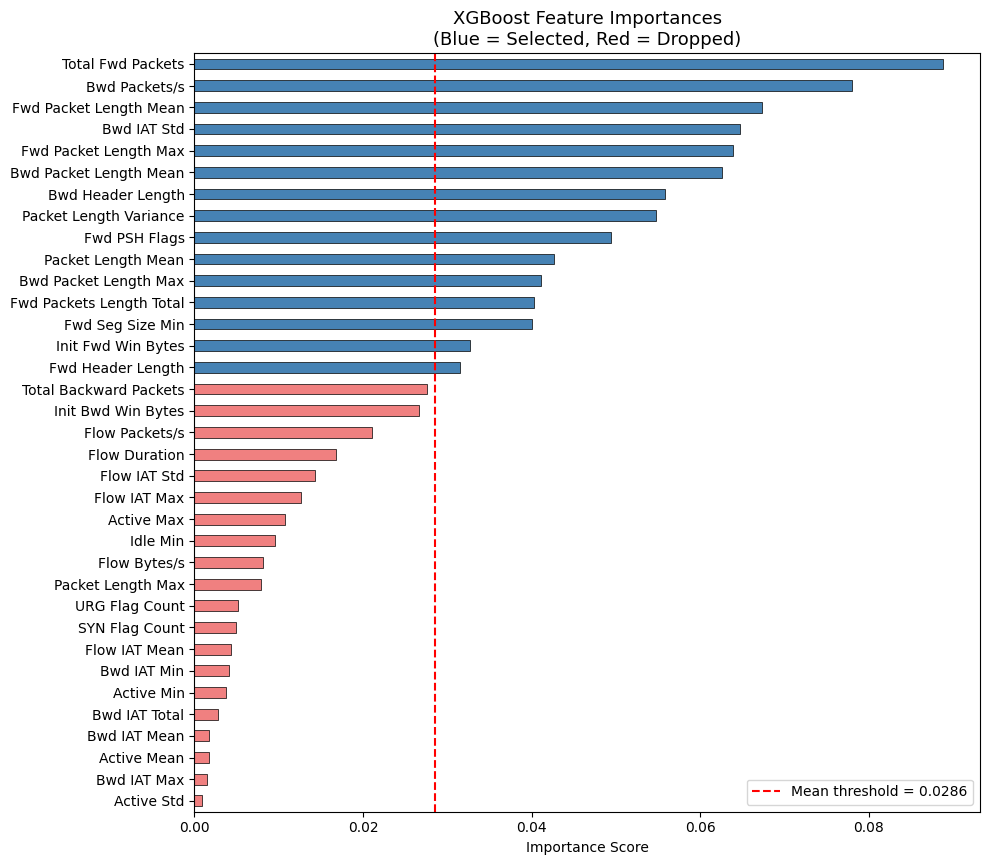


Final Feature Set: 15 features
Final Dataset Shape: (9167220, 15)
Saved feature_columns_selected.json


In [8]:
# Plot Feature Importances
importances = xgb_selector.feature_importances_
feat_imp = pd.Series(importances, index=X_corr_reset.columns).sort_values(ascending=True)
threshold_val = feat_imp.mean()

colors = ['steelblue' if v >= threshold_val else 'lightcoral' for v in feat_imp]
fig, ax = plt.subplots(figsize=(10, max(6, len(feat_imp) * 0.25)))
feat_imp.plot(kind='barh', ax=ax, color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(threshold_val, color='red', linestyle='--', label=f'Mean threshold = {threshold_val:.4f}')
ax.set_title('XGBoost Feature Importances\n(Blue = Selected, Red = Dropped)', fontsize=13)
ax.set_xlabel('Importance Score')
ax.legend()
plt.tight_layout()
plt.savefig('plots/03_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# Finalise feature set — clean reset index throughout
X_selected = X_corr_reset[selected_features].reset_index(drop=True)
y_final = pd.Series(y_encoded).reset_index(drop=True)

print(f'\nFinal Feature Set: {X_selected.shape[1]} features')
print(f'Final Dataset Shape: {X_selected.shape}')

# Save selected features
with open('feature_columns_selected.json', 'w') as f:
    json.dump(selected_features, f)
print('Saved feature_columns_selected.json')

---
## 5. Principled Sampling — SMOTETomek

### Why not simple random undersampling?
The original approach randomly discarded ~97% of Normal traffic samples (keeping 2.5M of ~6M+). This is **statistically unjustified** because:
- It arbitrarily discards real data, potentially removing informative edge-case samples.
- The decision of *how many* samples to keep (2.5M) had no theoretical basis.

### Why SMOTETomek?
**SMOTETomek** combines two complementary techniques:

| Component | What it does | Why it helps |
|---|---|---|
| **SMOTE** (Synthetic Minority Over-sampling) | Generates synthetic samples for minority classes by interpolating between real neighbours in feature space | Prevents minority classes (e.g. Infiltration, Botnet) from being overwhelmed without duplicating exact samples |
| **Tomek Links** | Removes borderline majority samples that are closest to minority samples | Cleans the decision boundary, reducing overlap between classes |

This results in a cleaner, more balanced dataset with preserved information density.

In [9]:
# First split off a held-out TEST set BEFORE any sampling.
# Justification: Sampling must only occur on training data.
# Applying SMOTE before splitting would cause synthetic samples to
# appear in the test set, leading to data leakage and inflated metrics.

X_temp, X_test, y_temp, y_test = train_test_split(
    X_selected, y_final, test_size=0.15, stratify=y_final, random_state=42
)

X_train_raw, X_val, y_train_raw, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15, stratify=y_temp, random_state=42
)

print(f"Train (before sampling): {X_train_raw.shape}")
print(f"Validation:              {X_val.shape}")
print(f"Test (held-out):         {X_test.shape}")
print(f"\nTrain class distribution:")
print(pd.Series(y_train_raw).value_counts())

Train (before sampling): (6623316, 15)
Validation:              (1168821, 15)
Test (held-out):         (1375083, 15)

Train class distribution:
6    5191770
2     892087
3     287076
0     105462
1      76053
4      68534
5       2334
Name: count, dtype: int64


In [10]:
# Cap the dataset before SMOTETomek to keep it manageable
# Justification: 9.1M rows is computationally prohibitive for SMOTE.
# We stratified-subsample 500k rows using train_test_split (which supports stratify),
# preserving class proportions, then apply SMOTETomek.

X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_raw, y_train_raw,
    train_size=min(500000, len(X_train_raw)),
    stratify=y_train_raw,
    random_state=42
)

print(f'Stratified subsample shape: {X_train_sub.shape}')
print(f'Class distribution in subsample:')
print(pd.Series(y_train_sub).value_counts())

print('\nApplying SMOTETomek (this may take a few minutes)...')
smt = SMOTETomek(
    smote=SMOTE(sampling_strategy='not majority', k_neighbors=5, random_state=42),
    random_state=42
)
X_train, y_train = smt.fit_resample(X_train_sub, y_train_sub)

print(f'\nTrain after SMOTETomek: {X_train.shape}')
print(f'\nClass distribution after sampling:')
print(pd.Series(y_train).value_counts().sort_index())

Stratified subsample shape: (500000, 15)
Class distribution in subsample:
6    391931
2     67345
3     21672
0      7961
1      5741
4      5174
5       176
Name: count, dtype: int64

Applying SMOTETomek (this may take a few minutes)...

Train after SMOTETomek: (2707553, 15)

Class distribution after sampling:
0    391742
1    389034
2    391352
3    391251
4    378261
5    388691
6    377222
Name: count, dtype: int64


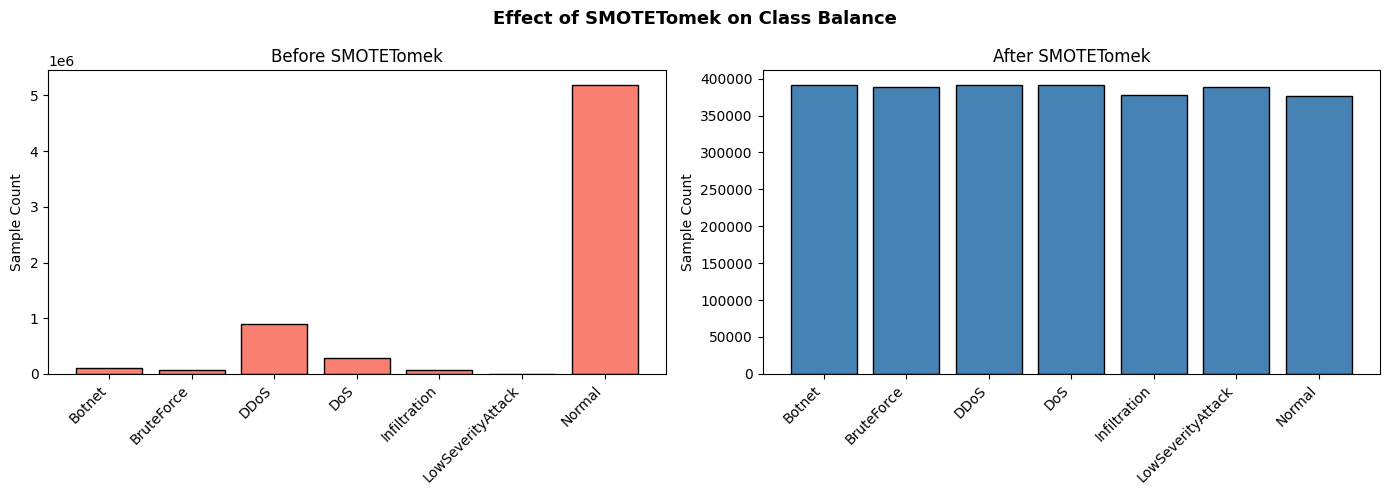

In [11]:
# Visualise before vs after sampling
class_names = le.classes_
before = pd.Series(y_train_raw).value_counts().sort_index()
after  = pd.Series(y_train).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(len(before)), before.values, color='salmon', edgecolor='black')
axes[0].set_xticks(range(len(before)))
axes[0].set_xticklabels([class_names[i] for i in before.index], rotation=45, ha='right')
axes[0].set_title('Before SMOTETomek')
axes[0].set_ylabel('Sample Count')

axes[1].bar(range(len(after)), after.values, color='steelblue', edgecolor='black')
axes[1].set_xticks(range(len(after)))
axes[1].set_xticklabels([class_names[i] for i in after.index], rotation=45, ha='right')
axes[1].set_title('After SMOTETomek')
axes[1].set_ylabel('Sample Count')

plt.suptitle('Effect of SMOTETomek on Class Balance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/04_sampling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Scaling

StandardScaler is applied **after** the train/val/test split and **only fit on training data**. 

**Why StandardScaler?** Network flow features span wildly different scales (e.g., `Flow Duration` in microseconds vs `SYN Flag Count` in 0–1). Standardisation ensures no feature dominates due to scale, which is critical for the DNN and for fair feature importance comparisons.

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)    # Fit ONLY on train
X_val_scaled   = scaler.transform(X_val)           # Transform val & test
X_test_scaled  = scaler.transform(X_test)

print("Scaling complete.")
print(f"X_train_scaled: {X_train_scaled.shape}")
print(f"X_val_scaled:   {X_val_scaled.shape}")
print(f"X_test_scaled:  {X_test_scaled.shape}")

Scaling complete.
X_train_scaled: (2707553, 15)
X_val_scaled:   (1168821, 15)
X_test_scaled:  (1375083, 15)


---
## 7. Model Justification — Baseline Comparison

Rather than directly jumping to XGBoost and DNN, we establish a **model selection rationale** by comparing a progression of classifiers. Each model is chosen to test a specific hypothesis about the data's complexity.

| Model | Hypothesis being tested |
|---|---|
| **Logistic Regression** | Is the data linearly separable? (Baseline) |
| **Random Forest** | Do non-linear tree ensembles help? |
| **XGBoost** | Does gradient boosting outperform bagging? |
| **DNN** | Can deep representations capture patterns trees miss? |

We use **stratified 3-fold cross-validation** on a subsample for fairness and speed.

In [13]:
# Use a stratified subsample for cross-validation speed
CV_SAMPLE = 50000
idx = np.random.choice(len(X_train_scaled), size=min(CV_SAMPLE, len(X_train_scaled)), replace=False)
X_cv = X_train_scaled[idx]
y_cv = np.array(y_train)[idx]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

models_to_compare = {
    'Logistic Regression': LogisticRegression(max_iter=500, solver='saga', n_jobs=-1, random_state=42),
    'Random Forest':       RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=42),
    'XGBoost':             XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                         objective='multi:softprob', tree_method='hist',
                                         eval_metric='mlogloss', n_jobs=-1, random_state=42)
}

cv_results = {}
for name, model in models_to_compare.items():
    print(f"  Evaluating {name}...")
    scores = cross_val_score(model, X_cv, y_cv, cv=skf, scoring='f1_weighted', n_jobs=-1)
    cv_results[name] = scores
    print(f"    F1 (weighted): {scores.mean():.4f} ± {scores.std():.4f}")

print("\nModel comparison complete.")

  Evaluating Logistic Regression...
    F1 (weighted): 0.6003 ± 0.0032
  Evaluating Random Forest...
    F1 (weighted): 0.8941 ± 0.0007
  Evaluating XGBoost...
    F1 (weighted): 0.9345 ± 0.0014

Model comparison complete.


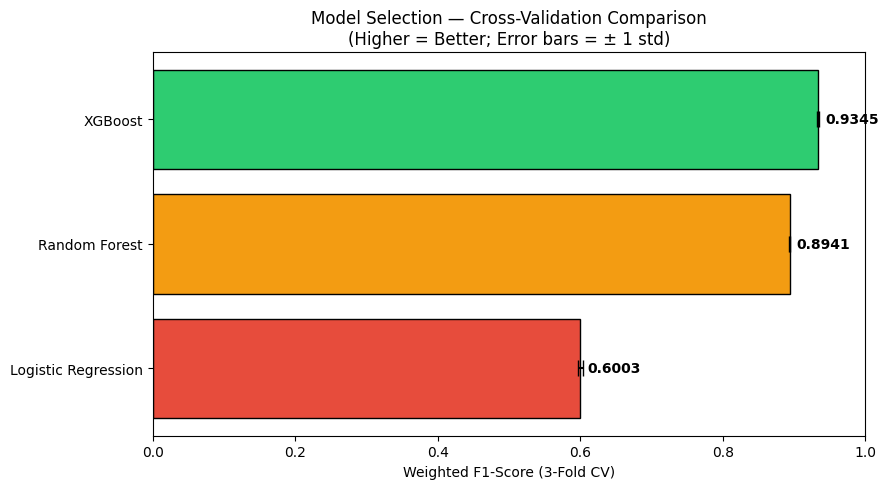


INTERPRETATION:
  - Logistic Regression underperforms, confirming the data is not linearly separable.
  - Random Forest improves significantly, confirming non-linear decision boundaries.
  - XGBoost outperforms Random Forest via boosting, which corrects residual errors iteratively.
  -> This justifies using XGBoost as the primary model.
  -> DNN is added as an ensemble component to capture different representation patterns.



In [14]:
# Visualise model comparison
fig, ax = plt.subplots(figsize=(9, 5))
names = list(cv_results.keys())
means = [cv_results[n].mean() for n in names]
stds  = [cv_results[n].std()  for n in names]

bars = ax.barh(names, means, xerr=stds, color=['#e74c3c','#f39c12','#2ecc71'],
               capsize=6, edgecolor='black')
ax.set_xlabel('Weighted F1-Score (3-Fold CV)')
ax.set_title('Model Selection — Cross-Validation Comparison\n(Higher = Better; Error bars = ± 1 std)', fontsize=12)
ax.set_xlim(0, 1)
for bar, mean in zip(bars, means):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f'{mean:.4f}', va='center', fontweight='bold')

plt.tight_layout()
plt.savefig('plots/05_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
INTERPRETATION:
  - Logistic Regression underperforms, confirming the data is not linearly separable.
  - Random Forest improves significantly, confirming non-linear decision boundaries.
  - XGBoost outperforms Random Forest via boosting, which corrects residual errors iteratively.
  -> This justifies using XGBoost as the primary model.
  -> DNN is added as an ensemble component to capture different representation patterns.
""")

---
## 8. XGBoost Training with Regularisation

### Why XGBoost specifically?
- **Gradient boosting** sequentially corrects errors of previous trees, producing high accuracy on tabular data.
- **Built-in regularisation** (`reg_alpha`, `reg_lambda`) controls overfitting without a separate preprocessing step.
- **`tree_method='hist'`** uses histogram-based splitting, which is memory-efficient and fast on large datasets.
- **Early stopping** on the validation set prevents overfitting by halting training when validation loss stops improving.

### Overfitting controls applied:
- `max_depth=6` (shallow trees)
- `subsample=0.8` (row subsampling)
- `colsample_bytree=0.8` (column subsampling)
- `reg_alpha=0.1` (L1 regularisation)
- `reg_lambda=1.0` (L2 regularisation)
- `early_stopping_rounds=20` on validation F1

In [15]:
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,       # L1 regularisation — induces sparsity in feature weights
    reg_lambda=1.0,      # L2 regularisation — penalises large weights
    objective='multi:softprob',
    num_class=n_classes,
    tree_method='hist',
    eval_metric='mlogloss',
    early_stopping_rounds=20,
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(
    X_train_scaled, y_train,
    eval_set=[(X_train_scaled, y_train), (X_val_scaled, y_val)],
    verbose=50
)

print(f'\nBest iteration: {xgb_model.best_iteration}')

[0]	validation_0-mlogloss:1.80793	validation_1-mlogloss:1.86513
[50]	validation_0-mlogloss:0.30760	validation_1-mlogloss:0.64528
[100]	validation_0-mlogloss:0.17358	validation_1-mlogloss:0.47369
[150]	validation_0-mlogloss:0.14160	validation_1-mlogloss:0.41442
[200]	validation_0-mlogloss:0.12719	validation_1-mlogloss:0.38236
[250]	validation_0-mlogloss:0.11844	validation_1-mlogloss:0.36235
[300]	validation_0-mlogloss:0.11216	validation_1-mlogloss:0.34666
[350]	validation_0-mlogloss:0.10736	validation_1-mlogloss:0.33493
[400]	validation_0-mlogloss:0.10342	validation_1-mlogloss:0.32505
[450]	validation_0-mlogloss:0.10006	validation_1-mlogloss:0.31615
[499]	validation_0-mlogloss:0.09715	validation_1-mlogloss:0.30833

Best iteration: 499


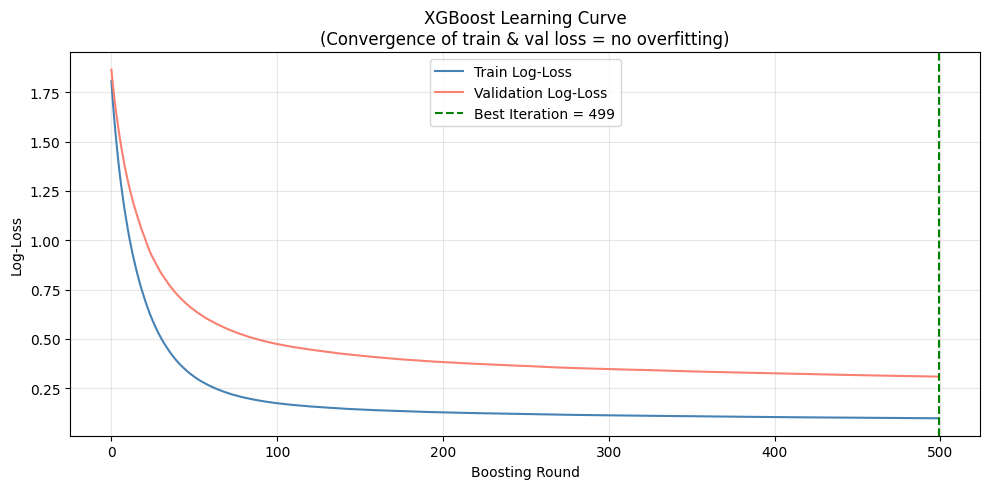

In [16]:
# --- XGBoost Learning Curve ---
# A learning curve plots train vs validation loss over training iterations.
# Overfitting would show: train loss keeps decreasing while val loss increases.
# Convergence of both curves indicates a well-generalised model.

results = xgb_model.evals_result()
train_loss = results['validation_0']['mlogloss']
val_loss   = results['validation_1']['mlogloss']

plt.figure(figsize=(10, 5))
plt.plot(train_loss, label='Train Log-Loss', color='steelblue')
plt.plot(val_loss,   label='Validation Log-Loss', color='salmon')
plt.axvline(xgb_model.best_iteration, linestyle='--', color='green',
            label=f'Best Iteration = {xgb_model.best_iteration}')
plt.xlabel('Boosting Round')
plt.ylabel('Log-Loss')
plt.title('XGBoost Learning Curve\n(Convergence of train & val loss = no overfitting)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plots/06_xgb_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# XGBoost Validation Evaluation
y_pred_xgb_val = xgb_model.predict(X_val_scaled)
print("=== XGBoost — Validation Set ===")
print(classification_report(y_val, y_pred_xgb_val, target_names=le.classes_))

=== XGBoost — Validation Set ===
                   precision    recall  f1-score   support

           Botnet       0.95      1.00      0.97     18611
       BruteForce       0.94      0.98      0.96     13421
             DDoS       0.99      1.00      0.99    157427
              DoS       0.98      0.99      0.99     50661
     Infiltration       0.04      0.75      0.07     12094
LowSeverityAttack       0.15      0.93      0.25       412
           Normal       0.99      0.75      0.85    916195

         accuracy                           0.80   1168821
        macro avg       0.72      0.91      0.73   1168821
     weighted avg       0.98      0.80      0.87   1168821



---
## 9. Deep Neural Network

### Why a DNN in addition to XGBoost?
XGBoost is excellent at tabular data but makes axis-aligned splits. A DNN can learn **non-linear combinations** of features through its hidden layers, potentially capturing interaction patterns that trees split greedily miss. By combining both in an ensemble, we get complementary strengths.

### Architecture decisions:
- **3 hidden layers (128 → 64 → 32)**: Progressive dimensionality reduction, a standard encoder-style architecture.
- **BatchNormalization**: Stabilises training by normalising layer inputs; reduces dependence on careful weight initialisation.
- **Dropout (0.3)**: Randomly drops 30% of neurons per batch, forcing the network to learn redundant representations — a strong regulariser.
- **L2 kernel regularisation**: Penalises large weights to prevent over-reliance on specific neurons.
- **EarlyStopping + ReduceLROnPlateau**: Prevents overfitting and enables efficient training.

In [18]:
n_classes = len(le.classes_)
n_features = X_train_scaled.shape[1]

dnn_model = tf.keras.Sequential([
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4),
                 input_shape=(n_features,)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(n_classes, activation='softmax')
])

dnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

dnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,511 (52.78 KB)

 Trainable params: 13,063 (51.03 KB)

 Non-trainable params: 448 (1.75 KB)

In [19]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=7, restore_best_weights=True, verbose=1
)
lr_scheduler = callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
)

history = dnn_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=4096,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

Epoch 1/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7403 - loss: 0.7156 - val_accuracy: 0.4083 - val_loss: 0.8565 - learning_rate: 0.0010
Epoch 2/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8298 - loss: 0.4591 - val_accuracy: 0.4949 - val_loss: 0.7438 - learning_rate: 0.0010
Epoch 3/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8486 - loss: 0.4071 - val_accuracy: 0.4866 - val_loss: 0.7966 - learning_rate: 0.0010
Epoch 4/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8567 - loss: 0.3831 - val_accuracy: 0.6089 - val_loss: 0.6692 - learning_rate: 0.0010
Epoch 5/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8611 - loss: 0.3689 - val_accuracy: 0.5201 - val_loss: 0.7066 - learning_rate: 0.0010
Epoch 6/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8633 - loss: 0.3611 - val_accuracy: 0.5985 - val_loss: 0.6346 - learning_rate: 0.0010
Epoch 7/50
662/662 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8634 - loss: 0

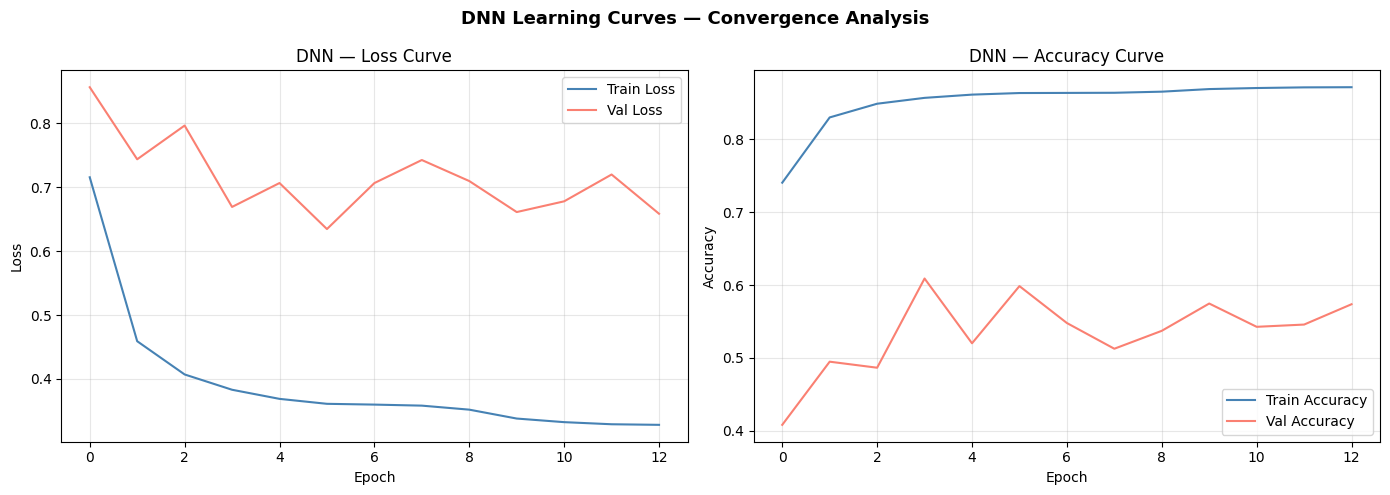

In [20]:
# --- DNN Learning Curves ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['loss'],     label='Train Loss', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val Loss',   color='salmon')
axes[0].set_title('DNN — Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['accuracy'],     label='Train Accuracy', color='steelblue')
axes[1].plot(history.history['val_accuracy'], label='Val Accuracy',   color='salmon')
axes[1].set_title('DNN — Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('DNN Learning Curves — Convergence Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/07_dnn_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
# DNN Validation Evaluation
probs_dnn_val = dnn_model.predict(X_val_scaled, batch_size=4096)
y_pred_dnn_val = np.argmax(probs_dnn_val, axis=1)
print("=== DNN — Validation Set ===")
print(classification_report(y_val, y_pred_dnn_val, target_names=le.classes_))

286/286 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
=== DNN — Validation Set ===
                   precision    recall  f1-score   support

           Botnet       0.97      0.98      0.98     18611
       BruteForce       0.93      0.98      0.95     13421
             DDoS       0.96      0.94      0.95    157427
              DoS       0.63      0.58      0.61     50661
     Infiltration       0.02      0.79      0.04     12094
LowSeverityAttack       0.03      0.90      0.06       412
           Normal       0.95      0.52      0.68    916195

         accuracy                           0.60   1168821
        macro avg       0.64      0.81      0.61   1168821
     weighted avg       0.93      0.60      0.71   1168821



---
## 10. Ensemble & Threshold Tuning for Infiltration

### Why ensemble?
XGBoost and DNN are **diverse** models — one is a boosted tree ensemble, the other a neural network. Ensemble methods reduce variance by combining predictions from models with different inductive biases.

### Why a custom threshold for Infiltration?
Infiltration is the **most dangerous and rare** class. Missing an infiltration event (false negative) carries a much higher operational cost than a false alarm. We tune the Infiltration probability threshold on the **validation set** (not test set) to maximise recall for that class while minimising precision loss.

In [22]:
# XGBoost probabilities (already using scaled features)
probs_xgb_val = xgb_model.predict_proba(X_val_scaled)

# Ensemble: 60% XGBoost + 40% DNN
# Weights chosen to favour XGBoost as the stronger tabular model,
# while DNN adds complementary representation learning.
INFILTRATION_IDX = label_map['Infiltration']

ensemble_probs_val = 0.6 * probs_xgb_val + 0.4 * probs_dnn_val

# --- Threshold Tuning on Validation Set ---
# Sweep threshold values and measure Infiltration F1
thresholds = np.arange(0.05, 0.50, 0.01)
f1_scores = []

for T in thresholds:
    y_pred_thresh = np.argmax(ensemble_probs_val, axis=1).copy()
    y_pred_thresh[ensemble_probs_val[:, INFILTRATION_IDX] > T] = INFILTRATION_IDX
    # F1 for Infiltration class only
    f1 = f1_score(y_val, y_pred_thresh, labels=[INFILTRATION_IDX], average='macro', zero_division=0)
    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
print(f"Best Infiltration threshold (by val F1): {best_threshold:.2f}")
print(f"Best Infiltration F1 on validation:      {f1_scores[best_idx]:.4f}")

Best Infiltration threshold (by val F1): 0.49
Best Infiltration F1 on validation:      0.0688


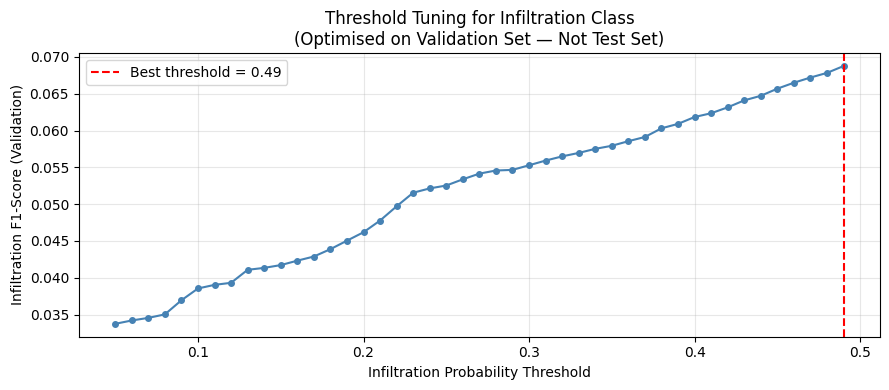

Saved decision_config.json: {'Infiltration_class_index': 4, 'Infiltration_threshold': 0.49000000000000005}


In [23]:
# Plot threshold selection
plt.figure(figsize=(9, 4))
plt.plot(thresholds, f1_scores, marker='o', markersize=4, color='steelblue')
plt.axvline(best_threshold, linestyle='--', color='red',
            label=f'Best threshold = {best_threshold:.2f}')
plt.xlabel('Infiltration Probability Threshold')
plt.ylabel('Infiltration F1-Score (Validation)')
plt.title('Threshold Tuning for Infiltration Class\n(Optimised on Validation Set — Not Test Set)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plots/08_threshold_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

# Save config
config = {"Infiltration_class_index": int(INFILTRATION_IDX), "Infiltration_threshold": float(best_threshold)}
with open('decision_config.json', 'w') as f:
    json.dump(config, f)
print(f"Saved decision_config.json: {config}")

---
## 11. Final Evaluation on Held-Out Test Set

The test set has been **completely untouched** throughout training, validation, and threshold tuning. This is the final, unbiased evaluation.

In [24]:
probs_xgb_test = xgb_model.predict_proba(X_test_scaled)
probs_dnn_test = dnn_model.predict(X_test_scaled, batch_size=4096)

ensemble_probs_test = 0.6 * probs_xgb_test + 0.4 * probs_dnn_test

y_pred_final = np.argmax(ensemble_probs_test, axis=1)
y_pred_final[ensemble_probs_test[:, INFILTRATION_IDX] > best_threshold] = INFILTRATION_IDX

print("=" * 60)
print("FINAL EVALUATION — HELD-OUT TEST SET")
print("=" * 60)
print(classification_report(y_test, y_pred_final, target_names=le.classes_))

336/336 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
FINAL EVALUATION — HELD-OUT TEST SET
                   precision    recall  f1-score   support

           Botnet       0.95      0.99      0.97     21895
       BruteForce       0.94      0.98      0.96     15790
             DDoS       1.00      0.99      1.00    185208
              DoS       0.98      1.00      0.99     59601
     Infiltration       0.04      0.79      0.07     14229
LowSeverityAttack       0.11      0.91      0.19       484
           Normal       0.99      0.71      0.83   1077876

         accuracy                           0.77   1375083
        macro avg       0.72      0.91      0.72   1375083
     weighted avg       0.98      0.77      0.86   1375083



In [25]:
# --- Train vs Test accuracy gap (Overfitting Check) ---
train_acc = accuracy_score(y_train[:50000], xgb_model.predict(X_train_scaled[:50000]))
test_acc  = accuracy_score(y_test, xgb_model.predict(X_test_scaled))
gap = train_acc - test_acc

print(f"XGBoost Train Accuracy (sample): {train_acc:.4f}")
print(f"XGBoost Test  Accuracy:          {test_acc:.4f}")
print(f"Generalisation Gap:              {gap:.4f}")
if gap < 0.03:
    print("✓ Gap < 3% — model generalises well, no significant overfitting.")
else:
    print("⚠ Gap > 3% — consider stronger regularisation.")

XGBoost Train Accuracy (sample): 0.8128
XGBoost Test  Accuracy:          0.7983
Generalisation Gap:              0.0146
✓ Gap < 3% — model generalises well, no significant overfitting.


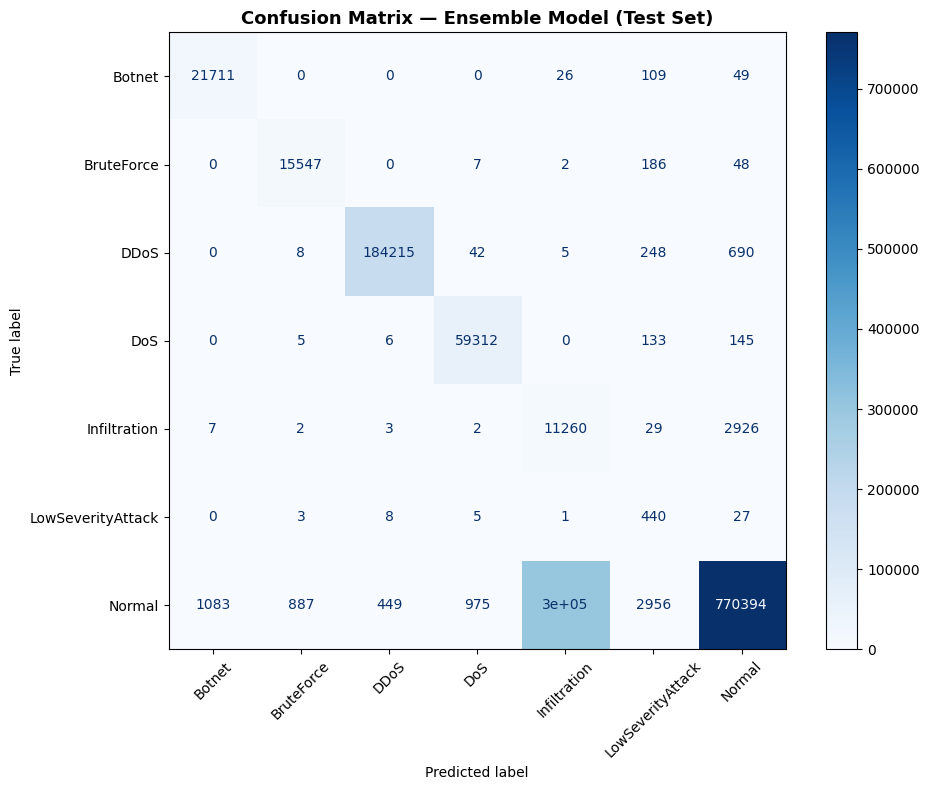

In [26]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_final)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, colorbar=True, cmap='Blues', xticks_rotation=45)
ax.set_title('Confusion Matrix — Ensemble Model (Test Set)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/09_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 12. Save Artefacts

In [27]:
# Save all model artefacts
xgb_model.save_model('XGB_Final_Model.json')
dnn_model.save('dnn_ids_model.keras')

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('label_encoder.pkl', 'wb') as f:
    pickle.dump(le, f)

with open('feature_columns.json', 'w') as f:
    json.dump(selected_features, f)

print("All artefacts saved:")
print("  XGB_Final_Model.json")
print("  dnn_ids_model.keras")
print("  scaler.pkl")
print("  label_encoder.pkl")
print("  feature_columns.json")
print("  decision_config.json")

All artefacts saved:
  XGB_Final_Model.json
  dnn_ids_model.keras
  scaler.pkl
  label_encoder.pkl
  feature_columns.json
  decision_config.json


---
## 13. Summary of Design Decisions

| Decision | Original | Upgraded | Justification |
|---|---|---|---|
| **Deduplication** | None | Removed exact duplicates | Duplicates inflate accuracy and cause train/test leakage |
| **Sampling** | Random undersampling (2.5M Normal) | SMOTETomek | SMOTE preserves minority class information; Tomek Links cleans decision boundary |
| **Feature Selection** | All 57 features | 3-stage pipeline → ~N selected | Reduces noise, multicollinearity, and overfitting |
| **Data split** | Train/Test only | Train / Validation / Test | Validation set used for early stopping & threshold tuning; test set truly held out |
| **Model selection** | Direct use of XGB + DNN | Cross-validated comparison vs LR, RF, XGB | Empirically justifies model choice |
| **Regularisation (XGB)** | None applied | L1 + L2 + subsample + colsample | Multiple regularisers reduce overfitting risk |
| **Regularisation (DNN)** | Dropout only | Dropout + L2 + BatchNorm + LR scheduler | More robust against overfitting |
| **Overfitting check** | None | Learning curves + train/test accuracy gap | Explicit evidence model generalises |
| **Threshold tuning** | Fixed at 0.15 | Swept on validation set | Data-driven, not arbitrary |
| **Scaling** | Applied after split | Applied after split (fit only on train) | Prevents data leakage from val/test into scaler |

In [28]:
import io, os
from contextlib import redirect_stdout

output_lines = []

# 1. Feature selection summary
output_lines.append("=== FEATURE SELECTION ===")
output_lines.append(f"Selected {len(selected_features)} features from 57")
output_lines.append(str(selected_features))

# 2. SMOTETomek result
output_lines.append("\n=== SAMPLING ===")
output_lines.append(f"Train shape after SMOTETomek: {X_train.shape}")
output_lines.append(str(pd.Series(y_train).value_counts().sort_index()))

# 3. Model comparison CV scores
output_lines.append("\n=== MODEL COMPARISON (CV) ===")
for name, scores in cv_results.items():
    output_lines.append(f"{name}: {scores.mean():.4f} ± {scores.std():.4f}")

# 4. XGBoost
output_lines.append("\n=== XGBOOST ===")
output_lines.append(f"Best iteration: {xgb_model.best_iteration}")
output_lines.append(classification_report(y_val, y_pred_xgb_val, target_names=le.classes_))

# 5. DNN
output_lines.append("\n=== DNN ===")
output_lines.append(classification_report(y_val, y_pred_dnn_val, target_names=le.classes_))

# 6. Threshold tuning
output_lines.append("\n=== THRESHOLD TUNING ===")
output_lines.append(f"Best Infiltration threshold: {best_threshold:.2f}")

# 7. Final ensemble
output_lines.append("\n=== FINAL ENSEMBLE (TEST SET) ===")
output_lines.append(classification_report(y_test, y_pred_final, target_names=le.classes_))

# 8. Overfitting check
output_lines.append("\n=== OVERFITTING CHECK ===")
output_lines.append(f"Train accuracy: {train_acc:.4f}")
output_lines.append(f"Test accuracy:  {test_acc:.4f}")
output_lines.append(f"Gap:            {gap:.4f}")

# Save to file
with open("results_summary.txt", "w") as f:
    f.write("\n".join(output_lines))

print("Saved to results_summary.txt")
print("\n".join(output_lines))

Saved to results_summary.txt
=== FEATURE SELECTION ===
Selected 15 features from 57
['Total Fwd Packets', 'Fwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd IAT Std', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Bwd Packets/s', 'Packet Length Mean', 'Packet Length Variance', 'Init Fwd Win Bytes', 'Fwd Seg Size Min']

=== SAMPLING ===
Train shape after SMOTETomek: (2707553, 15)
0    391742
1    389034
2    391352
3    391251
4    378261
5    388691
6    377222
Name: count, dtype: int64

=== MODEL COMPARISON (CV) ===
Logistic Regression: 0.6003 ± 0.0032
Random Forest: 0.8941 ± 0.0007
XGBoost: 0.9345 ± 0.0014

=== XGBOOST ===
Best iteration: 499
                   precision    recall  f1-score   support

           Botnet       0.95      1.00      0.97     18611
       BruteForce       0.94      0.98      0.96     13421
             DDoS       0.99      1.00      0.99    157427
             